# 04 · Evaluate the liver fat model

How accurate is the model from `03_train_liver_model.ipynb`, and is it good enough to show on
the Liver card? This notebook tests the **saved artifact as is** on:

- **Internal test:** the 25% of 2017–March 2020 adults held out from training (same split as notebook 03).
- **External test:** NHANES **August 2021–August 2023**, a later, independent sample the model never saw.

The label is elastography CAP ≥ 285 dB/m (liver fat). It's compared with ALT alone and with two
published scores that need BMI, which lab reports don't include: the Hepatic Steatosis Index
(HSI; Lee et al. 2010) and the Fatty Liver Index (FLI; Bedogni et al. 2006).

All estimates use NHANES exam weights, so they describe the US adult population. Intervals are
95% bootstrap intervals. Run notebooks 01 and 03 first.

In [1]:
import sys
from pathlib import Path

ML_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ML_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nhanes  # also puts backend/ on the path
from biomarkers import PANELS

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
DATA = ML_DIR / "data"


In [2]:
import json
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from evaluation import (bootstrap_ci, calibration_summary, hide, prepare_liver, subgroups, threshold_for,
                        weighted_auc, weighted_rates)

ARTIFACT = ML_DIR / "artifacts" / "liver_fatty_liver" / "v1"
model = joblib.load(ARTIFACT / "model.joblib")
meta = json.loads((ARTIFACT / "metadata.json").read_text())
X_COLS = meta["features"]
LABS = [c for c in X_COLS if c not in ("age", "male")]

development = prepare_liver(pd.read_parquet(DATA / "nhanes_2017_2020_adults.parquet"))
train, internal = train_test_split(development, test_size=0.25, random_state=0, stratify=development["fatty_liver"])
assert len(train) == meta["training_rows"], "split differs from notebook 03; re-run it"
external = prepare_liver(pd.read_parquet(DATA / "nhanes_2021_2023_adults.parquet"))

prevalence = lambda d: np.average(d["fatty_liver"], weights=d["weight"])
pd.DataFrame({
    "adults": [len(train), len(internal), len(external)],
    "CAP ≥ 285 (weighted)": [prevalence(train), prevalence(internal), prevalence(external)],
}, index=["training (2017–20)", "internal test (2017–20)", "external test (2021–23)"]).style.format({"CAP ≥ 285 (weighted)": "{:.1%}"})

,adults,CAP ≥ 285 (weighted)
training (2017–20),5825,36.2%
internal test (2017–20),1942,34.7%
external test (2021–23),5525,34.0%


## Comparators

- **ALT only:** logistic regression on log(ALT), fit on the same training split.
- **HSI** = 8 × ALT/AST + BMI (+2 if female, +2 if diabetic).
- **FLI** = 100 × eʸ / (1 + eʸ), y = 0.953 ln(TG) + 0.139 BMI + 0.718 ln(GGT) + 0.053 waist − 15.745.
- **Model + BMI:** the same model retrained with BMI added, to show what asking users for BMI would gain.

In [3]:
def hsi(d):
    return 8 * d["ALT"] / d["AST"] + d["bmi"] + 2 * (d["sex"] == "female") + 2 * d["diabetes"].fillna(0)


def fli(d):
    y = 0.953 * np.log(d["Triglycerides"]) + 0.139 * d["bmi"] + 0.718 * np.log(d["GGT"]) + 0.053 * d["waist_cm"] - 15.745
    return 100 * np.exp(y) / (1 + np.exp(y))


def hide_values(frame, rate, seed):
    return hide(frame, LABS, rate, seed)


alt_ok = train["ALT"].notna()
alt_only = LogisticRegression().fit(np.log(train.loc[alt_ok, ["ALT"]]), train.loc[alt_ok, "fatty_liver"], sample_weight=train.loc[alt_ok, "weight"])
bmi_ok = train["bmi"].notna()
aug = pd.concat([train[bmi_ok], hide_values(train[bmi_ok], 0.25, seed=1)])
with_bmi = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=0)
with_bmi.fit(aug[X_COLS + ["bmi"]], aug["fatty_liver"], sample_weight=aug["weight"])

SCORERS = {
    "Model (labs + age + sex)": lambda d: model.predict_proba(d[X_COLS])[:, 1],
    "ALT only": lambda d: alt_only.predict_proba(np.log(d[["ALT"]]))[:, 1],
    "HSI (needs BMI)": hsi,
    "FLI (needs BMI, waist)": fli,
    "Model + BMI": lambda d: with_bmi.predict_proba(d[X_COLS + ["bmi"]])[:, 1],
}
NEEDS = {"ALT only": ["ALT"], "HSI (needs BMI)": ["ALT", "AST", "bmi"], "FLI (needs BMI, waist)": ["Triglycerides", "GGT", "bmi", "waist_cm"],
         "Model + BMI": ["bmi"], "Model (labs + age + sex)": []}

## Discrimination (AUROC)

AUROC is the chance the model ranks a random person with fatty liver above one without
(0.5 = coin flip, 1 = perfect). Each comparator is scored on people who have its inputs.

In [4]:
rows = []
for name, scorer in SCORERS.items():
    for label, frame in [("internal", internal), ("external", external)]:
        d = frame.dropna(subset=NEEDS[name])
        d = d[np.isfinite(scorer(d))]
        auc = weighted_auc(d, scorer(d))
        low, high = bootstrap_ci(d, lambda s: weighted_auc(s, scorer(s)))
        rows.append({"score": name, "test set": label, "adults": len(d), "AUROC": auc, "95% CI": f"{low:.3f}–{high:.3f}"})
discrimination = pd.DataFrame(rows).pivot(index="score", columns="test set", values=["AUROC", "95% CI", "adults"])
discrimination = discrimination.reindex(list(SCORERS))
discrimination

AUROC                 95% CI                adults         
test set                  external  internal     external     internal external internal
score                                                                                   
Model (labs + age + sex)  0.734923  0.732377  0.718–0.750  0.699–0.769     5525     1942
ALT only                  0.683109  0.686016  0.661–0.702  0.647–0.721     4971     1809
HSI (needs BMI)           0.821046  0.821094  0.807–0.835  0.794–0.846     4933     1784
FLI (needs BMI, waist)    0.851374  0.841364  0.834–0.870  0.802–0.877     2688      864
Model + BMI               0.834676  0.833739  0.822–0.848  0.804–0.859     5490     1924

## Calibration

Is a predicted 40% risk really 40%? Compares predicted risk with the observed share of people
with fatty liver, on the external test set.

,mean predicted,observed,calibration slope,expected calibration error,Brier
internal,0.360,0.347,0.722,0.041,0.195
external,0.348,0.340,0.740,0.040,0.194


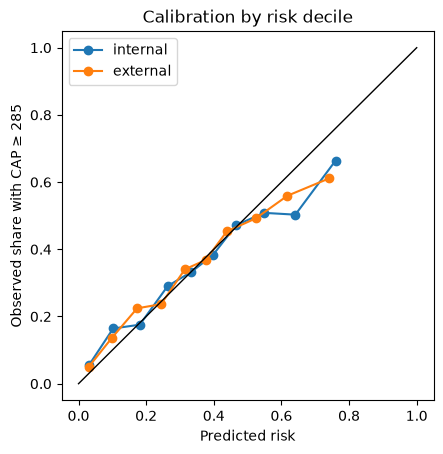

In [5]:
calibration_rows, curves = {}, {}
for label, frame in [("internal", internal), ("external", external)]:
    p = model.predict_proba(frame[X_COLS])[:, 1]
    calibration_rows[label], curves[label] = calibration_summary(frame, p)
display(pd.DataFrame(calibration_rows).T.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(4.8, 4.8))
for label, per_bin in curves.items():
    ax.plot(per_bin["predicted"], per_bin["observed"], marker="o", label=label)
ax.plot([0, 1], [0, 1], color="black", linewidth=1)
ax.set(xlabel="Predicted risk", ylabel="Observed share with CAP ≥ 285", title="Calibration by risk decile")
ax.legend()
plt.show()

A calibration slope near 1 and mean predicted ≈ observed mean the risks can be shown as
percentages. A slope below 1 means predictions are too extreme; above 1, too timid.

## What a cut-off would mean for users

If the Liver card flagged "likely fatty liver" above a threshold, how often would it be right?
The 90%-sensitivity and 90%-specificity thresholds are chosen on the internal test set and then
applied unchanged to the external set.

In [6]:
p_internal = model.predict_proba(internal[X_COLS])[:, 1]
p_external = model.predict_proba(external[X_COLS])[:, 1]
thresholds = {
    "90% sensitivity (rule out)": threshold_for(internal, p_internal, sensitivity=0.9),
    "0.5": 0.5,
    "90% specificity (rule in)": threshold_for(internal, p_internal, specificity=0.9),
}
pd.DataFrame({name: weighted_rates(external, p_external, t) for name, t in thresholds.items()}).T.style.format(
    {"threshold": "{:.3f}", "flagged": "{:.1%}", "sensitivity": "{:.1%}", "specificity": "{:.1%}", "PPV": "{:.1%}", "NPV": "{:.1%}"})

,threshold,flagged,sensitivity,specificity,PPV,NPV
90% sensitivity (rule out),0.176,71.5%,90.0%,38.0%,42.7%,88.0%
0.5,0.500,27.7%,46.8%,82.1%,57.3%,75.0%
90% specificity (rule in),0.619,15.7%,28.0%,90.6%,60.5%,71.0%


## Subgroups (external test)

A model shown to everyone should work comparably across groups.

In [7]:
subgroups(external, p_external).style.format({"fatty liver": "{:.1%}", "AUROC": "{:.3f}", "mean predicted": "{:.1%}"})

,adults,fatty liver,mean predicted,AUROC,95% CI
group,,,,,
sex: female,2992,29.7%,29.6%,0.751,0.730–0.774
sex: male,2533,38.3%,40.2%,0.710,0.681–0.739
race_ethnicity: Mexican American,396,42.0%,38.1%,0.728,0.668–0.780
race_ethnicity: Non-Hispanic Asian,326,30.3%,34.0%,0.757,0.681–0.839
race_ethnicity: Non-Hispanic Black,656,28.4%,35.8%,0.675,0.620–0.721
race_ethnicity: Non-Hispanic White,3216,34.8%,33.9%,0.750,0.730–0.776
race_ethnicity: Other Hispanic,565,33.9%,38.0%,0.700,0.646–0.759
race_ethnicity: Other/Multiracial,366,29.4%,34.7%,0.712,0.635–0.784
age_band: 18–39,1635,25.4%,24.7%,0.770,0.738–0.806


## Reports with missing tests (external test)

A US comprehensive metabolic panel has no GGT; some reports only have AST and ALT.

In [8]:
def blank(d, columns):
    out = d.copy()
    out[columns] = np.nan
    return out


scenarios = {
    "all liver tests": external,
    "no GGT (typical CMP)": blank(external, ["GGT"]),
    "AST + ALT only": blank(external, [c for c in LABS if c not in ("AST", "ALT")]),
    "25% of values hidden at random": hide_values(external, 0.25, seed=3),
    "50% of values hidden at random": hide_values(external, 0.50, seed=4),
}
pd.DataFrame({name: {"AUROC": weighted_auc(d, model.predict_proba(d[X_COLS])[:, 1])} for name, d in scenarios.items()}).T.style.format("{:.3f}")

,AUROC
all liver tests,0.735
no GGT (typical CMP),0.711
AST + ALT only,0.702
25% of values hidden at random,0.716
50% of values hidden at random,0.686


## Which inputs matter

Permutation importance: how much external AUROC drops when one input is shuffled.

In [9]:
importance = permutation_importance(model, external[X_COLS], external["fatty_liver"], scoring="roc_auc",
                                    sample_weight=external["weight"], n_repeats=10, random_state=0)
pd.DataFrame({"AUROC drop": importance.importances_mean, "sd": importance.importances_std}, index=X_COLS).sort_values(
    "AUROC drop", ascending=False).style.format("{:.3f}")

,AUROC drop,sd
ALT,0.099,0.007
GGT,0.069,0.004
age,0.031,0.003
AST,0.014,0.003
Albumin/Globulin Ratio,0.006,0.002
Alkaline Phosphatase,0.004,0.002
Albumin,0.003,0.001
"Bilirubin, Total",0.003,0.001
Globulin,0.002,0.001
male,0.002,0.001


## Summary

In [10]:
auc = lambda name, label: discrimination.loc[name, ("AUROC", label)]
summary = {
    "external AUROC": round(auc("Model (labs + age + sex)", "external"), 3),
    "external AUROC 95% CI": discrimination.loc["Model (labs + age + sex)", ("95% CI", "external")],
    "internal AUROC": round(auc("Model (labs + age + sex)", "internal"), 3),
    "ALT-only external AUROC": round(auc("ALT only", "external"), 3),
    "HSI external AUROC (with BMI)": round(auc("HSI (needs BMI)", "external"), 3),
    "FLI external AUROC (with BMI, waist)": round(auc("FLI (needs BMI, waist)", "external"), 3),
    "model + BMI external AUROC": round(auc("Model + BMI", "external"), 3),
    "external calibration slope": round(calibration_rows["external"]["calibration slope"], 3),
    "external mean predicted vs observed": [round(calibration_rows["external"]["mean predicted"], 3), round(calibration_rows["external"]["observed"], 3)],
}
(ARTIFACT / "evaluation.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "external AUROC": 0.735,
  "external AUROC 95% CI": "0.718\u20130.750",
  "internal AUROC": 0.732,
  "ALT-only external AUROC": 0.683,
  "HSI external AUROC (with BMI)": 0.821,
  "FLI external AUROC (with BMI, waist)": 0.851,
  "model + BMI external AUROC": 0.835,
  "external calibration slope": 0.74,
  "external mean predicted vs observed": [
    0.348,
    0.34
  ]
}


## Verdict

- **It generalizes.** External AUROC (2021–23) matches internal (2017–20), so the model isn't
  overfit to one survey cycle, and it beats ALT alone — the test people usually look at.
- **It's a moderate screen, not a diagnosis.** AUROC ≈ 0.73 means it ranks people correctly
  about three times in four. At the rule-out threshold it catches 90% of fatty livers but flags
  most adults; at the rule-in threshold its positive predictions are right only ~60% of the time.
- **BMI is the missing ingredient.** Published scores that use BMI (HSI, FLI) and the same model
  with BMI added reach AUROC ≈ 0.82–0.85. Asking users for height and weight would help more than
  any lab change.
- **Risks are slightly too extreme** (calibration slope < 1) though correct on average;
  recalibrating (e.g. isotonic or Platt scaling on a held-out set) would fix that before showing
  percentages.
- **Weaker for some groups** — older adults and Non-Hispanic Black adults have lower AUROC, and
  the model over-predicts for Non-Hispanic Black adults. That should be stated on the card or
  addressed before release.
- **Limits of the label.** CAP ≥ 285 dB/m is itself an imperfect measure of liver fat, and NHANES is
  a US sample; reports from other countries (like the Sterling sample) may behave differently.